In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("Hazır")

Hazır


In [2]:
rng = np.random.default_rng(42)
n = 200
sicaklik = rng.uniform(5, 35, n).round(1)
hafta_sonu = rng.integers(0, 2, n)
kampanya = rng.integers(0, 2, n)
satis = (40 + 3 * sicaklik + 25 * hafta_sonu + 18 * kampanya + rng.normal(0, 10, n)).round(0)
df = pd.DataFrame({"Sicaklik": sicaklik, "Hafta_Sonu": hafta_sonu, "Kampanya": kampanya, "Satis": satis})
print(df.head())
print(df.describe().round(1))

   Sicaklik  Hafta_Sonu  Kampanya  Satis
0      28.2           1         1  172.0
1      18.2           1         1  143.0
2      30.8           0         1  153.0
3      25.9           1         0  129.0
4       7.8           0         1   58.0
       Sicaklik  Hafta_Sonu  Kampanya  Satis
count     200.0       200.0     200.0  200.0
mean       19.8         0.5       0.6  121.7
std         8.5         0.5       0.5   31.5
min         5.2         0.0       0.0   45.0
25%        12.6         0.0       0.0   98.0
50%        19.4         1.0       1.0  122.0
75%        27.4         1.0       1.0  147.0
max        34.8         1.0       1.0  186.0


In [3]:
df

,Sicaklik,Hafta_Sonu,Kampanya,Satis
0,28.2,1,1,172.0
1,18.2,1,1,143.0
2,30.8,0,1,153.0
3,25.9,1,0,129.0
4,7.8,0,1,58.0
...,...,...,...,...
195,10.4,1,0,85.0
196,23.0,1,1,149.0
197,31.2,1,0,148.0
198,10.9,1,0,105.0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sicaklik,200.0,19.8145,8.476313,5.2,12.575,19.4,27.425,34.8
Hafta_Sonu,200.0,0.5150,0.501029,0.0,0.000,1.0,1.000,1.0
Kampanya,200.0,0.5500,0.498742,0.0,0.000,1.0,1.000,1.0
Satis,200.0,121.7000,31.474006,45.0,98.000,122.0,147.000,186.0


In [5]:
df.isnull().sum()

Sicaklik      0
Hafta_Sonu    0
Kampanya      0
Satis         0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Sicaklik    200 non-null    float64
 1   Hafta_Sonu  200 non-null    int64  
 2   Kampanya    200 non-null    int64  
 3   Satis       200 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 6.4 KB


In [7]:
df.tail()

,Sicaklik,Hafta_Sonu,Kampanya,Satis
195,10.4,1,0,85.0
196,23.0,1,1,149.0
197,31.2,1,0,148.0
198,10.9,1,0,105.0
199,14.3,1,0,128.0


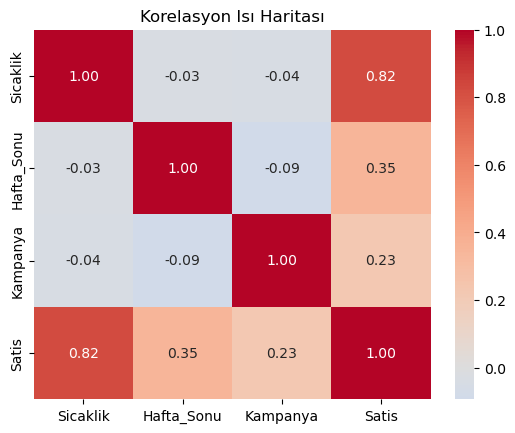

In [10]:
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f",center=0)
plt.title("Korelasyon Isı Haritası")
plt.show()

In [8]:
X=df.drop("Satis",axis=1)
y=df["Satis"]

In [9]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [11]:
ham_model = LinearRegression().fit(X_train,y_train)
print("Keşisim:",round(ham_model.intercept_,1))
for ad,k in zip(X.columns,ham_model.coef_):
    print(f"{ad:12s} katsayı:{k:6.2f}")

Keşisim: 36.1
Sicaklik     katsayı:  3.09
Hafta_Sonu   katsayı: 26.38
Kampanya     katsayı: 18.54


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
model = LinearRegression().fit(X_train_scaled,y_train)
pred_ham=ham_model.predict(X_test)
pred=model.predict(X_test_scaled)
print("İki modelin tahminleri aynı mı?", np.allclose(pred_ham, pred))
print("Ölçeklenmiş katsayılar:", {k: round(float(v), 1) for k, v in zip(X.columns, model.coef_)})

İki modelin tahminleri aynı mı? True
Ölçeklenmiş katsayılar: {'Sicaklik': 26.6, 'Hafta_Sonu': 13.2, 'Kampanya': 9.2}


In [14]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)
print(f"MAE : {mae:.2f} adet")
print(f"RMSE: {rmse:.2f} adet")
print(f"R2  : {r2:.2f}")

MAE : 8.73 adet
RMSE: 10.66 adet
R2  : 0.87


In [15]:
skorlar = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5 fold R2 skorları:", skorlar.round(3))
print(f"Ortalama: {skorlar.mean():.3f} | Std: {skorlar.std():.3f}")

5 fold R2 skorları: [0.907 0.892 0.857 0.903 0.923]
Ortalama: 0.896 | Std: 0.022
